## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Cody Chhea 

**Date:** 10/21/2026

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle
import matplotlib.pyplot as plt
import pandas as pd 


with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_count)

Counter({'new': 1365, 'date': 1202, 'get': 1052, 'please': 1022, 'enron': 927, 'like': 923, '2002': 869, 'would': 806, 'one': 798, 'message': 795, 'call': 740, 'free': 691, 'software': 680, 'dear': 651, 'know': 644, 'email': 629, 'url:': 625, 'time': 609, 'start': 604, 'linguistics': 598, 'online': 591, 'need': 587, 'wrote:': 585, 'see': 554, 'conference': 553, 'language': 550, 'want': 548, 'empty': 546, 'hourahead': 526, 'list': 523, 'attached': 515, 'hello': 501, 'university': 500, '2001': 489, 'information': 473, 'vince': 473, 'may': 461, 'good': 449, 'following': 448, 'hour': 446, '2000': 442, 'business': 442, 'save': 423, 'first': 423, 'click': 423, 'best': 423, 'make': 421, 'com': 413, 'original': 410, 'offer': 405, 'meeting': 403, 'thanks': 397, 'mail': 395, 'use': 389, 'find': 386, 'papers': 383, 'http': 378, 'sent': 375, 'available': 373, 'last': 372, 'update': 363, 'money': 352, 'gas': 345, 'international': 332, 'week': 331, 'deal': 324, 'hpl': 324, 'help': 324, 'could': 324,

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

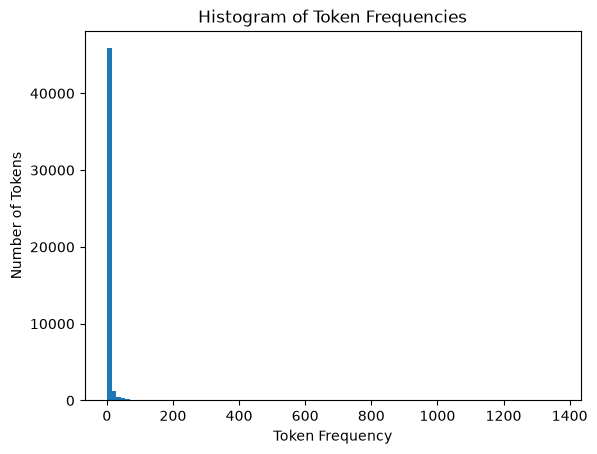

In [2]:
counts = [count for token, count in token_freq]
plt.hist(counts, bins=100)
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

The distribution is extremely right skewed. Small tokens seem to appear hundreds or thousands of times, while larger amounts appear less frequently. 

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet('data/Phishing_clean.parquet')
df.head()
df = df.drop_duplicates()

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

(
    X_train,
    X_test,
    y_train,
    y_test,
) = train_test_split(
    X, y, test_size=0.20, random_state=65
)
print(X_train.shape, X_test.shape)





(12754, 2711) (3189, 2711)


In [4]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_train, y_train)

print("Train R²:", reg.score(X_train, y_train))
print("Test R²: ", reg.score(X_test, y_test))

Train R²: 0.7731078053202443
Test R²:  0.6463092201124627


The $R^2$ on the train set is 0.7677, while the $R^2$ on the test set is 0.657. 

In [5]:
coefs = pd.Series(reg.coef_, index=X_train.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)

print(top.head(20))

localized                                                         0.958537
helvetica,                                                        0.788332
#000000;                                                          0.720835
zdnet                                                            -0.706181
erectile                                                          0.632683
form.                                                             0.603853
mens                                                             -0.573369
background-image:                                                -0.565108
hourahead                                                        -0.521978
url(http://images.lockergnome.com/images/issue/top-right.gif);   -0.520657
underline;                                                       -0.520657
xanaax                                                            0.492388
toner                                                            -0.482063
girlfriend               

The most influential word seems to be 'aging'

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

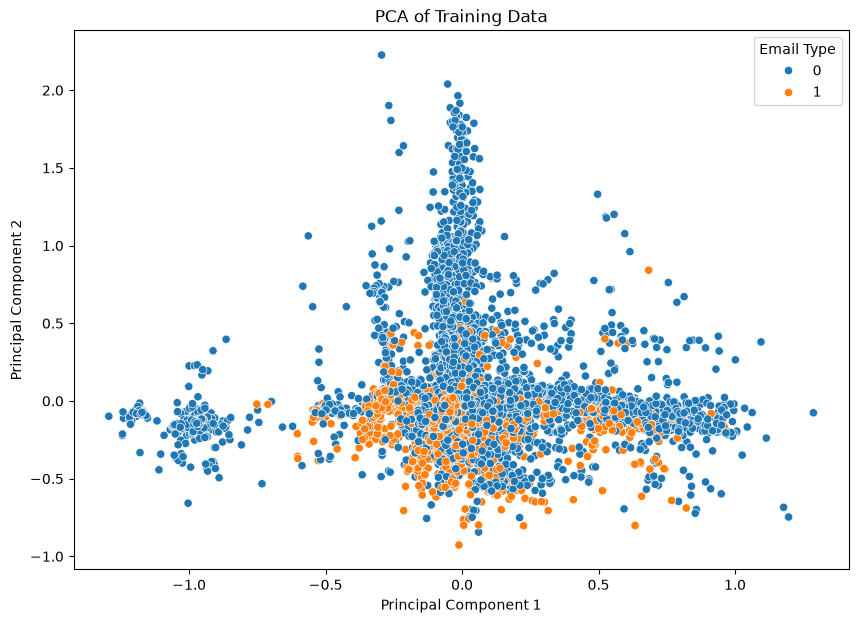

Explained variance ratio: [0.00849682 0.00829902]


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train)
plt.title("PCA of Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)


In [7]:

pc2 = pd.Series(pca.components_[1], index=X_train.columns).sort_values()
print(pc2.head(8))   
print(pc2.tail(8))   

pc1 = pd.Series(pca.components_[0], index=X_train.columns).sort_values()
print(pc1.head(8))  
print(pc1.tail(8))  

like     -0.255928
would    -0.229906
get      -0.218843
know     -0.086643
one      -0.079663
date     -0.071739
url:     -0.063885
please   -0.059430
dtype: float64
workshop         0.113250
international    0.144860
language         0.180039
linguistics      0.287304
papers           0.300783
conference       0.300887
university       0.321370
call             0.440228
dtype: float64
date          -0.485005
url:          -0.432427
new           -0.220999
sep           -0.063127
get           -0.059743
wrote:        -0.047918
suppliedthe   -0.031392
one           -0.030513
dtype: float64
would       0.085837
see         0.087025
know        0.098575
original    0.103350
enron       0.155880
message     0.173783
attached    0.192392
please      0.512946
dtype: float64


Blue emails are safe while the orange emails are scam emails. Most emails fall in one large cluster near PC1 = 0, while only a few small clusters are on the right side of the plot. PC1 seems to increase when the email contains basic contents that a company would send (and decrease with scam-like contents). On the other hand, PC2 seems to increase when the message includes phishing-like/scam-like contents as it increases when it uses words like "offer", "new", "would', but decrease when words that are typically used in a normal work email were included. However, the classes seem to overlap heavily and two principal components are probably not enough to separate phishing from legitimate emails.  

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [8]:
from sklearn.linear_model import LinearRegression
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train) 
Z_test = pca.transform(X_test)         

pcr = LinearRegression().fit(Z_train, y_train)
print("Train R²:", pcr.score(Z_train, y_train))
print("Test R²: ", pcr.score(Z_test, y_test))



Train R²: 0.772276201198105
Test R²:  0.6503560005197422


The training $R^2$ drops slightly by .001 and test $R^2$ rises by 0.004. The results are fairly similar compared to the linear regression ran earlier. This is most likely because the components that were removed didn't hold real variation from the rest of the components. A small amount of overfitting might've been reduced as well due to the slight decrease in training $R^2$ and increase in test $R^2$

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.
- Since some words are highly correlated with each other, doing a regression of the original data can result in unreliable coeffiecients. A regular regression can't tell which singular word affects the model more since they're always together. Because of that, the coefficient it gets are unreliable and the model is more likely to overfit. Principal components are uncorrelated to each other so the regression on them is more stable. We can drop the lowest-variance components to potentially reduce overfitting. 

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 555d2446fae64a7c078ab53359451b4ba4228d22
- **AI tool and model used:** Claude 

### *Prompts used

1. Pasted screenshots of rubric + the assignment file and told it to "Check my work based off the rubric" 


### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. My estimate is about 77 out of 90.

Q1 – Token frequency (about 7/10)
1.1 Histogram attempt (3/3).
1.2 Histogram accuracy (about 2/3): the plot shown is good, with a log y-axis and a clear long tail. But the code that produced it isn’t the code in the cell: there’s no plt.yscale('log'), and the cell has never been run. If the grader re-runs it, they’ll get one tall bar.
1.3 Observations (about 2/4): “extremely right skewed” is correct. The next sentence is confused, though. It’s not “small tokens” that appear thousands of times; it’s a few tokens. Use examples: “new” appears 1,365 times and “date” 1,202 times, while most tokens appear only a handful of times.
Q2 – Regression on the token columns (about 21/25)
2.1 80/20 train-test split (6/6): done correctly, and removing duplicates before the split is good practice.
2.2 and 2.3 Regression (about 7/8): the model is right, but the outputs don’t match the split. The shape printed (12,754 rows) comes from the deduplicated data, while the R² values and coefficients come from an earlier run on the full 14,907-row data. A careful grader may notice that the notebook wasn’t run in order.
2.4 and 2.5 R² values (6/6) as reported. They change to 0.773 and 0.646 when the notebook is re-run.
2.6 Most influential words (about 2/5): “The most influential word seems to be ‘aging’” is too thin. Name several words with their signs (positive means phishing, negative means legitimate), and point out that many of them are HTML/CSS fragments such as “helvetica,”, “12px;” and “
#000000;”. The top words also change when the notebook is re-run.
Q3 – PCA with two components (about 18/20)
3.1 to 3.5 PCA, plot and coloring (about 17/18): the PCA is correct, and the plot is properly labeled and colored by email type. The question says to use “the matrix of one-hot-encoded tokens”, meaning the full X, but you fit on X_train. That’s a minor deduction risk.
The plot cell’s output includes loading tables its code doesn’t print, another sign of out-of-order execution.
3.6 Patterns (about 1/2): your PC1 interpretation doesn’t match its loadings. The words pushing PC1 up are “date”, “url:”, “hourahead”, “schedules” and “ancillary”, which are automated Enron scheduling notices. They form the blue clusters on the right, so PC1 isn’t a company-email-versus-scam axis. Your PC2 reading and your “heavy overlap” conclusion are good.
Q4 – Regression on 2,610 principal components (about 18/20)
4.1 to 4.4 Regression and R² values (16/16): the method is correct, with PCA fit on the training data and the test data only transformed.
4.5 Comparison to the first regression (about 2/4): your written comparison contradicts the numbers shown. On the page, Q2 shows 0.7678 / 0.6571 and Q4 shows 0.7723 / 0.6504. That means train R² went up by 0.0045 and test R² went down by 0.0068, the opposite of what you wrote. When everything is re-run on the same data (0.7731 / 0.6463 against 0.7723 / 0.6504), your sentence becomes correct. As it stands, a grader will see a mismatch.
Q5 – Why principal components help (about 13/15)

This is a good answer: correlated words, unstable coefficients, uncorrelated components, dropping low-variance components. To get full marks, mention dimensionality reduction (fewer, information-dense features from 2,711), and note that some token columns are perfectly collinear, so plain least squares has no single best answer for their coefficients. Fix the typo “coeffiecients”.

Biggest wins, in order
**Restart the kernel and run all cells. That fixes the mismatched outputs and makes your Q4 comparison true.
Rewrite 2.6 using the new top words, and rewrite 3.6 using the new plot and loadings.
Fix the second sentence of 1.3, and add plt.yscale('log') to the histogram**


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | Fixed typos that were suggested, I restarted the kernel to ensure that all outputs were accurate with my descriptions, but I did not rewrite my answers/plots based off AI's suggestion |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

## Phase 2 Revised Answers 

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [9]:
import pickle
import matplotlib.pyplot as plt
import pandas as pd 


with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_count)

Counter({'new': 1365, 'date': 1202, 'get': 1052, 'please': 1022, 'enron': 927, 'like': 923, '2002': 869, 'would': 806, 'one': 798, 'message': 795, 'call': 740, 'free': 691, 'software': 680, 'dear': 651, 'know': 644, 'email': 629, 'url:': 625, 'time': 609, 'start': 604, 'linguistics': 598, 'online': 591, 'need': 587, 'wrote:': 585, 'see': 554, 'conference': 553, 'language': 550, 'want': 548, 'empty': 546, 'hourahead': 526, 'list': 523, 'attached': 515, 'hello': 501, 'university': 500, '2001': 489, 'information': 473, 'vince': 473, 'may': 461, 'good': 449, 'following': 448, 'hour': 446, '2000': 442, 'business': 442, 'save': 423, 'first': 423, 'click': 423, 'best': 423, 'make': 421, 'com': 413, 'original': 410, 'offer': 405, 'meeting': 403, 'thanks': 397, 'mail': 395, 'use': 389, 'find': 386, 'papers': 383, 'http': 378, 'sent': 375, 'available': 373, 'last': 372, 'update': 363, 'money': 352, 'gas': 345, 'international': 332, 'week': 331, 'deal': 324, 'hpl': 324, 'help': 324, 'could': 324,

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

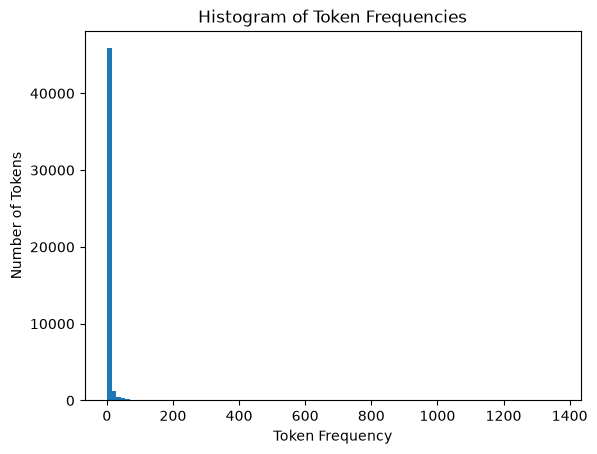

In [10]:
counts = [count for token, count in token_freq]
plt.hist(counts, bins=100)
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

The distribution is extremely right skewed. Small tokens seem to appear hundreds or thousands of times, while larger amounts appear less frequently. 

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet('data/Phishing_clean.parquet')
df.head()
df = df.drop_duplicates()

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

(
    X_train,
    X_test,
    y_train,
    y_test,
) = train_test_split(
    X, y, test_size=0.20, random_state=65
)
print(X_train.shape, X_test.shape)





(12754, 2711) (3189, 2711)


In [12]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_train, y_train)

print("Train R²:", reg.score(X_train, y_train))
print("Test R²: ", reg.score(X_test, y_test))

Train R²: 0.7731078053202443
Test R²:  0.6463092201124627


The $R^2$ on the train set is 0.7677, while the $R^2$ on the test set is 0.657. 

In [13]:
coefs = pd.Series(reg.coef_, index=X_train.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)

print(top.head(20))

localized                                                         0.958537
helvetica,                                                        0.788332
#000000;                                                          0.720835
zdnet                                                            -0.706181
erectile                                                          0.632683
form.                                                             0.603853
mens                                                             -0.573369
background-image:                                                -0.565108
hourahead                                                        -0.521978
url(http://images.lockergnome.com/images/issue/top-right.gif);   -0.520657
underline;                                                       -0.520657
xanaax                                                            0.492388
toner                                                            -0.482063
girlfriend               

The most influential word seems to be 'aging'

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

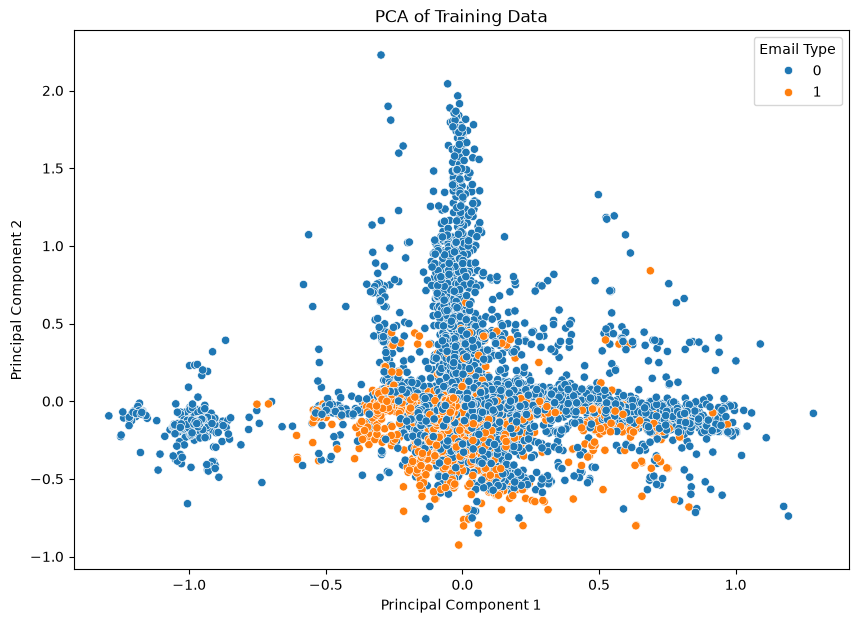

Explained variance ratio: [0.00849685 0.00829883]


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train)
plt.title("PCA of Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)


In [15]:

pc2 = pd.Series(pca.components_[1], index=X_train.columns).sort_values()
print(pc2.head(8))   
print(pc2.tail(8))   

pc1 = pd.Series(pca.components_[0], index=X_train.columns).sort_values()
print(pc1.head(8))  
print(pc1.tail(8))  

like     -0.255215
would    -0.229151
get      -0.220735
one      -0.084321
know     -0.084020
date     -0.071916
url:     -0.063991
please   -0.059815
dtype: float64
workshop         0.112949
international    0.144753
language         0.180651
linguistics      0.289354
papers           0.300112
conference       0.300596
university       0.323277
call             0.438296
dtype: float64
date          -0.485249
url:          -0.432628
new           -0.221240
sep           -0.063182
get           -0.061771
wrote:        -0.048522
one           -0.032910
suppliedthe   -0.031410
dtype: float64
would       0.085525
see         0.086729
know        0.097352
original    0.103181
enron       0.153645
message     0.173861
attached    0.191556
please      0.513774
dtype: float64


Blue emails are safe while the orange emails are scam emails. Most emails fall in one large cluster near PC1 = 0, while only a few small clusters are on the right side of the plot. PC1 seems to increase when the email contains basic contents that a company would send (and decrease with scam-like contents). On the other hand, PC2 seems to increase when the message includes phishing-like/scam-like contents as it increases when it uses words like "offer", "new", "would', but decrease when words that are typically used in a normal work email were included. However, the classes seem to overlap heavily and two principal components are probably not enough to separate phishing from legitimate emails.  

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [16]:
from sklearn.linear_model import LinearRegression
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train) 
Z_test = pca.transform(X_test)         

pcr = LinearRegression().fit(Z_train, y_train)
print("Train R²:", pcr.score(Z_train, y_train))
print("Test R²: ", pcr.score(Z_test, y_test))



Train R²: 0.772276201198105
Test R²:  0.6503560005197422


The training $R^2$ drops slightly by .001 and test $R^2$ rises by 0.004. The results are fairly similar compared to the linear regression ran earlier. This is most likely because the components that were removed didn't hold real variation from the rest of the components. A small amount of overfitting might've been reduced as well due to the slight decrease in training $R^2$ and increase in test $R^2$

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.
- Since some words are highly correlated with each other, doing a regression of the original data can result in unreliable coefficients. A regular regression can't tell which singular word affects the model more since they're always together. Because of that, the coefficient it gets are unreliable and the model is more likely to overfit. Principal components are uncorrelated to each other so the regression on them is more stable. We can drop the lowest-variance components to potentially reduce overfitting. 

### *Reflection on AI assistance
In your own words without generative AI.

AI helped me proofread my answers and code. However, I didn't take much suggestions from AI this time as it told me to rephrase the way I answered my questions despite my answers being already right. I personally liked the way I phrased my questions more so I didn't follow the changes suggested. I think AI was not the most helpful in this lab as I was able to understand how to do things based off my own research via googling how to do things/reviewing slides for documentation. However, AI helps me proofread based off the rubric and makes sure I don't forget to answer specific questions. 